[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_recovery/BA_L2_recovery.ipynb)

# BA_L2_recovery: The Gain Needed to Recover

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

The gain d/(1-d) needed to recover a drawdown d, with the maximum drawdowns of the S&P 500, Bitcoin and Ethereum since 2016; with the Bitcoin drawdown of 2021-2022 and its recovery worked out step by step.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Data and method

`close_cal(sym, start)` keeps each asset on its own calendar: crypto trades every day; for the S&P 500 and gold only
Monday–Friday closes are kept and repeated closes (holidays filled with the last price) are removed.
`log_returns(sym)` gives the daily log returns in percent, $r_t = 100(\ln P_t - \ln P_{t-1})$, of 2018–2026.

The drawdown on day $t$ is $D_t = P_t/\max_{s \le t} P_s - 1$. A loss of $d$ needs a gain of $d/(1-d)$ to return to the
record. Maximum drawdowns are computed on daily closes since 1 January 2016.

**How to read the chart.** The red curve rises faster than the dotted line (gain equal to loss) and explodes as $d$
approaches 100%; the points are the deepest falls of the three assets.

In [5]:
from scipy import stats
import statsmodels.api as sm


def close_cal(sym, start, end=END):
    # closes on the asset's own calendar: crypto every day; S&P 500 and gold Monday-Friday, repeated closes removed
    s = daily(sym, end).loc[start:]
    if not sym.endswith('.CC'):
        s = s[s.index.dayofweek < 5]
        s = s[s.diff() != 0]
    return s


def log_returns(sym, start='2017-12-31', first='2018-01-01', end=END):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1}), from `first`
    return (100 * np.log(close_cal(sym, start, end)).diff()).dropna().loc[first:]

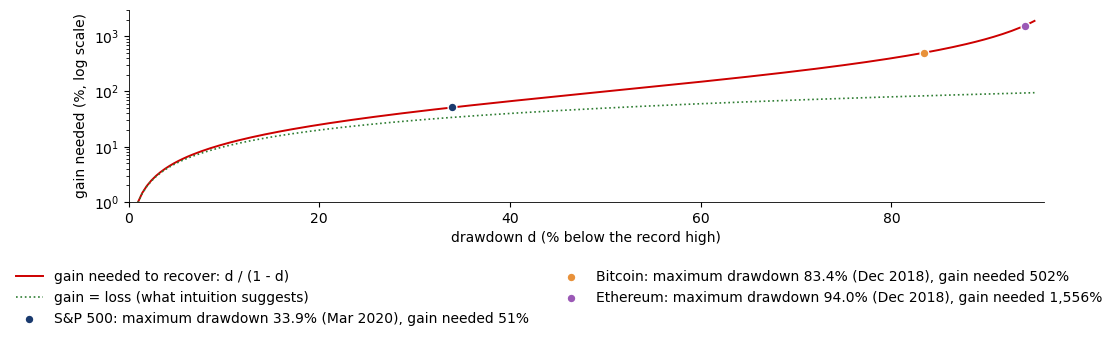

S&P 500: maximum drawdown 33.9% on 23 Mar 2020; gain needed 51%
Bitcoin: maximum drawdown 83.4% on 15 Dec 2018; gain needed 502%
Ethereum: maximum drawdown 94.0% on 14 Dec 2018; gain needed 1556%


In [6]:
# the gain needed to recover a drawdown d is d / (1 - d); maximum drawdowns since 2016
d_grid = np.linspace(0, 0.95, 200)
mdd = {}
for nm, sym in [('S&P 500', 'GSPC.INDX'), ('Bitcoin', 'BTC-USD.CC'), ('Ethereum', 'ETH-USD.CC')]:
    p_ = close_cal(sym, '2016-01-01')
    dd_ = p_ / p_.cummax() - 1
    mdd[nm] = (-dd_.min(), dd_.idxmin())

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(100 * d_grid, 100 * d_grid / (1 - d_grid), color=RED, lw=1.4, label='gain needed to recover: d / (1 - d)')
ax.plot(100 * d_grid, 100 * d_grid, color=GREEN, ls=':', lw=1.2, label='gain = loss (what intuition suggests)')
for nm, col in [('S&P 500', BLUE), ('Bitcoin', BTC), ('Ethereum', ETH)]:
    d_, t_ = mdd[nm]
    ax.scatter([100 * d_], [100 * d_ / (1 - d_)], color=col, s=40, zorder=5, edgecolor='white',
               label=f'{nm}: maximum drawdown {100 * d_:.1f}% ({t_:%b %Y}), gain needed {100 * d_ / (1 - d_):,.0f}%')
ax.set_yscale('log'); ax.set_ylim(1, 3000); ax.set_xlim(0, 96)
ax.set_xlabel('drawdown d (% below the record high)'); ax.set_ylabel('gain needed (%, log scale)')
legend_below(fig, ncol=2, bottom=0.22)
save_fig(fig, 'ba_l2_recovery')
for nm, (d_, t_) in mdd.items():
    print(f'{nm}: maximum drawdown {100 * d_:.1f}% on {t_:%d %b %Y}; gain needed {100 * d_ / (1 - d_):.0f}%')

The Bitcoin drawdown from the record of November 2021, step by step.

In [7]:
# worked example: the Bitcoin drawdown of November 2021 - November 2022 and its recovery
pb_ = close_cal('BTC-USD.CC', '2014-09-17')
pk_ = pb_.loc['2021-01-01':'2022-01-01'].idxmax(); peak_ = pb_[pk_]
tr_ = pb_.loc[pk_:'2023-12-31'].idxmin(); trough_ = pb_[tr_]
rec_ = pb_.loc[tr_:][pb_.loc[tr_:] > peak_].index[0]
d_ = 1 - trough_ / peak_
print(f'Peak {pk_:%d %b %Y}: {peak_:,.0f} USD; trough {tr_:%d %b %Y}: {trough_:,.0f} USD')
print(f'Drawdown d = 1 - {trough_:,.0f} / {peak_:,.0f} = {100 * d_:.1f}%')
print(f'Gain needed d / (1 - d) = {d_:.3f} / {1 - d_:.3f} = {100 * d_ / (1 - d_):.0f}%  (= {peak_:,.0f} / {trough_:,.0f} - 1)')
print(f'New record {rec_:%d %b %Y}: {(rec_ - pk_).days} days after the peak, {(rec_ - tr_).days} days after the trough')
yrs = (rec_ - tr_).days / 365
print(f'Growth from the trough to the record: ({peak_:,.0f} / {trough_:,.0f})^(1/{yrs:.2f}) - 1 = {100 * ((peak_ / trough_) ** (1 / yrs) - 1):.0f}% a year')
print(f'Time to recover at a steady 50% a year: ln({peak_ / trough_:.2f}) / ln(1.5) = {np.log(peak_ / trough_) / np.log(1.5):.1f} years')

Peak 08 Nov 2021: 67,567 USD; trough 21 Nov 2022: 15,787 USD
Drawdown d = 1 - 15,787 / 67,567 = 76.6%
Gain needed d / (1 - d) = 0.766 / 0.234 = 328%  (= 67,567 / 15,787 - 1)
New record 04 Mar 2024: 847 days after the peak, 469 days after the trough
Growth from the trough to the record: (67,567 / 15,787)^(1/1.28) - 1 = 210% a year
Time to recover at a steady 50% a year: ln(4.28) / ln(1.5) = 3.6 years
